In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

def get_input_path(filename):
    """Automatically resolves file path in Kaggle input datasets, working dir, or local directory."""
    if os.path.exists(filename):
        return filename
    for root, _, files in os.walk('/kaggle/input'):
        if filename in files:
            return os.path.join(root, filename)
    for root, _, files in os.walk('/kaggle/working'):
        if filename in files:
            return os.path.join(root, filename)
    return filename

df = pd.read_parquet(get_input_path('master_df_merged.parquet'))
df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,...,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards,age_group,income_group,debt_group
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,...,46.799999,-100.760002,23679.0,48277.0,110153.0,740,4,20-40,Middle,High
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,...,40.799999,-91.120003,18076.0,36853.0,112139.0,834,5,40-60,Lower-Middle,High
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,...,33.180000,-117.290001,16894.0,34449.0,36540.0,686,3,40-60,Lower-Middle,Lower-Middle
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,...,41.419998,-87.349998,26168.0,53350.0,128676.0,685,5,40-60,Middle,Highest
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,...,38.860001,-76.599998,33529.0,68362.0,96182.0,711,2,40-60,High,High


In [5]:
card_df = pd.read_csv(get_input_path('cleaned_card_data.csv'))
card_df.head()

,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed
0,4524,825,Visa,Debit,4344676511950444,2022-12,623,True,2,24295.0,2002-09,2008
1,2731,825,Visa,Debit,4956965974959986,2020-12,393,True,2,21968.0,2014-04,2014
2,3701,825,Visa,Debit,4582313478255491,2024-02,719,True,2,46414.0,2003-07,2004
3,42,825,Visa,Credit,4879494103069057,2024-08,693,False,1,12400.0,2003-01,2012
4,4659,825,Mastercard,Debit (Prepaid),5722874738736011,2009-03,75,True,1,28.0,2008-09,2009


In [ ]:
card_df.shape

(6146, 12)

In [6]:
master_df = df.merge(card_df, how = 'left', left_on='card_id', right_on='id')

In [8]:
import gc
vars_to_del = ['user_df', 'df']

for var in vars_to_del:
    if var in globals():
        del globals()[var]

# Force garbage collection
gc.collect()

print("RAM cleared.")

RAM cleared.


In [ ]:
master_df.head()

,id_x,date,time,client_id_x,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,...,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,...,Mastercard,Debit (Prepaid),5497590243197280,2022-07,306,True,2,55.0,2008-05,2008
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,...,Mastercard,Credit,5175842699412235,2024-12,438,True,1,9100.0,2005-09,2015
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,...,Mastercard,Debit,5874992802287595,2020-05,256,True,1,14802.0,2006-01,2008
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,...,Mastercard,Debit,5346827663529174,2024-10,54,False,2,37634.0,2004-05,2006
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,...,Visa,Debit,4354185735186651,2020-01,120,True,1,19113.0,2009-07,2014


In [7]:
master_df.drop(columns=['id_y', 'id_x', 'client_id_y'], inplace=True)

In [ ]:
def downcast_dtypes(df, money_cols=None, skip_cols=None):
    money_cols = money_cols or []
    skip_cols = skip_cols or []

    for col in df.columns:
        if col in skip_cols or df[col].dtype.name in ('category',) or pd.api.types.is_datetime64_any_dtype(df[col]):
            continue
        if col in money_cols:
            df[col] = df[col].astype('float32')
        elif pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='integer')
        elif pd.api.types.is_float_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='float')
    return df

master_df = downcast_dtypes(master_df, money_cols=['card_number', 'credit_limmit'])

In [9]:
master_df.columns

Index(['date', 'time', 'client_id_x', 'card_id', 'amount', 'use_chip',
       'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc',
       'errors', 'abs_amount', 'target', 'target_numeric', 'amount_bins',
       'current_age', 'retirement_age', 'birth_year', 'birth_month', 'gender',
       'address', 'latitude', 'longitude', 'per_capita_income',
       'yearly_income', 'total_debt', 'credit_score', 'num_credit_cards',
       'age_group', 'income_group', 'debt_group', 'card_brand', 'card_type',
       'card_number', 'expires', 'cvv', 'has_chip', 'num_cards_issued',
       'credit_limit', 'acct_open_date', 'year_pin_last_changed'],
      dtype='object')

In [11]:
master_df.to_parquet('client_id.parquet')

# Univariate Analysis

### card_brand

In [ ]:
master_df['card_brand'].value_counts(normalize=True)*100

,proportion
card_brand,
Mastercard,53.791107
Visa,37.258340
Amex,6.421881
Discover,2.528672


- Mastercard and Visa is used most

### card_type

In [ ]:
master_df['card_type'].value_counts(normalize=True)*100

,proportion
card_type,
Debit,62.235449
Credit,30.882423
Debit (Prepaid),6.882127


- Debit card is used in high volume

### has_chip

In [ ]:
master_df['has_chip'].value_counts(normalize=True)*100

,proportion
has_chip,
True,89.996028
False,10.003972


- 90% of the cards have a chip

### credit_limit

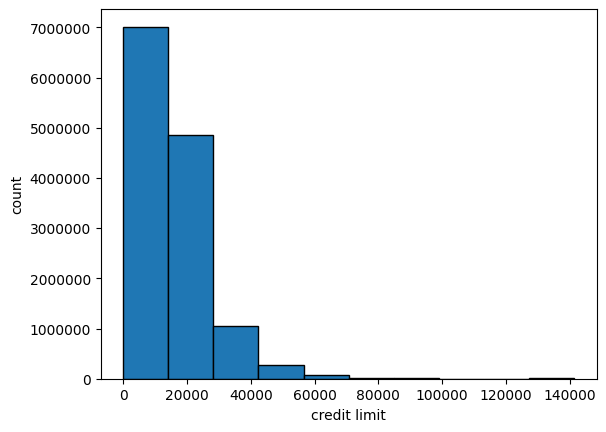

In [ ]:
plt.hist(master_df['credit_limit'], edgecolor='black')
plt.ticklabel_format(style='plain')
plt.xlabel('credit limit')
plt.ylabel('count')
plt.show()

- Most of the cards offer credit limit between 0 to 2.5k

# Bivariate Analysis

### card_brand vs target

<Axes: xlabel='target', ylabel='card_brand'>

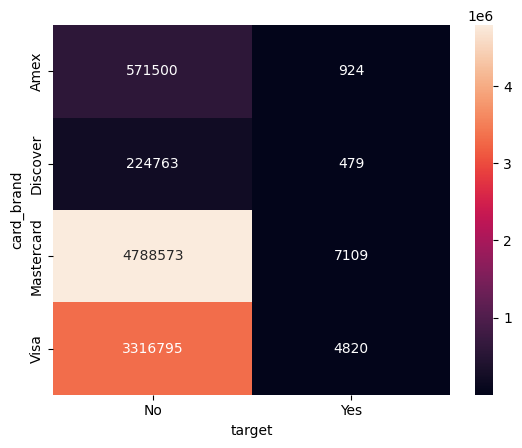

In [ ]:
sns.heatmap(pd.crosstab(master_df['card_brand'], master_df['target']), annot=True, fmt='d')

In [ ]:
card_brand_fraud = master_df.groupby('card_brand').agg(total_txns = ('target', 'size'), fraud_count = ('target', lambda x: (x=='Yes').sum()))

card_brand_fraud['fraud_rate'] = card_brand_fraud['fraud_count']/card_brand_fraud['total_txns']*100
card_brand_fraud.sort_values(by='fraud_rate', ascending=False)

,total_txns,fraud_count,fraud_rate
card_brand,,,
Discover,336463,479,0.142363
Amex,854490,924,0.108135
Mastercard,7157399,7109,0.099324
Visa,4957563,4820,0.097225


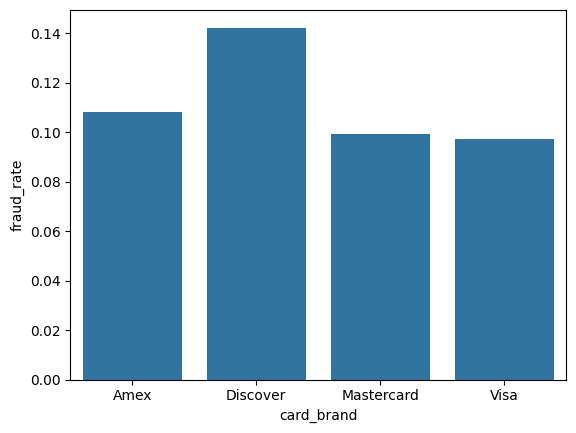

In [ ]:
sns.barplot(x = card_brand_fraud.index,y= card_brand_fraud['fraud_rate'])
plt.show()

### card_type vs target

In [ ]:
card_type_fraud = master_df.groupby('card_type').agg(total_txns = ('target', 'size'), fraud_count = ('target', lambda x: (x=='Yes').sum()))

card_type_fraud['fraud_rate'] = card_type_fraud['fraud_count']/card_type_fraud['total_txns']*100
card_type_fraud.sort_values(by='fraud_rate', ascending=False)

,total_txns,fraud_count,fraud_rate
card_type,,,
Debit (Prepaid),915730,1378,0.150481
Credit,4109189,4490,0.109267
Debit,8280996,7464,0.090134


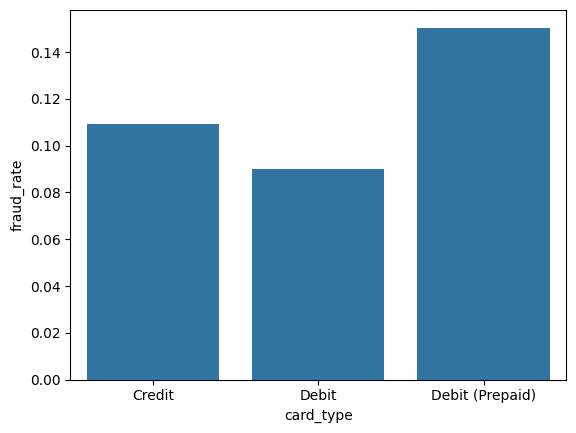

In [ ]:
sns.barplot(x = card_type_fraud.index,y= card_type_fraud['fraud_rate'])
plt.show()

### has_chip vs target

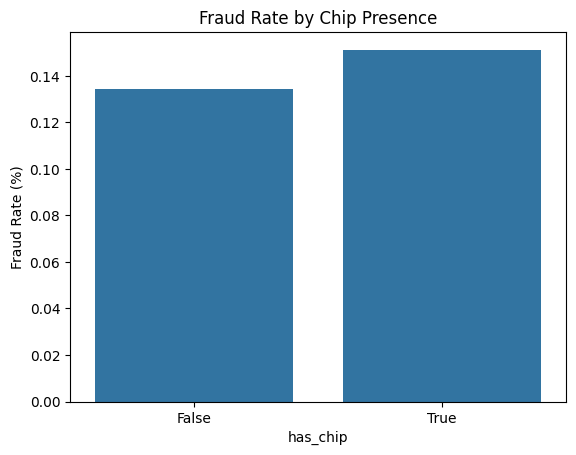

In [ ]:
has_chip_fraud = master_df.groupby('has_chip')['target_numeric'].mean() * 100
sns.barplot(x=has_chip_fraud.index, y=has_chip_fraud.values)
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate by Chip Presence')
plt.show()

### credit_limit_bin vs target

In [ ]:
master_df['credit_limit_bin'] = pd.qcut(master_df['credit_limit'], q=[0,0.25,0.5,0.75,0.9, 1.], labels=['0-25%', '25-50%', '50-75%', '75-90%', '90-100%'])

In [ ]:
limit_fraud = master_df.groupby('credit_limit_bin').agg(total_txns = ('target', 'size'), fraud_count = ('target', lambda x: (x=='Yes').sum()))

limit_fraud['fraud_rate'] = limit_fraud['fraud_count']/limit_fraud['total_txns']*100
limit_fraud.sort_values(by='fraud_rate', ascending=False)

/tmp/ipykernel_592/2374718081.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  limit_fraud = master_df.groupby('credit_limit_bin').agg(total_txns = ('target', 'size'), fraud_count = ('target', lambda x: (x=='Yes').sum()))


,total_txns,fraud_count,fraud_rate
credit_limit_bin,,,
0-25%,3341126,4178,0.125048
25-50%,3314063,3293,0.099364
75-90%,1995407,1853,0.092863
50-75%,3324850,3046,0.091613
90-100%,1330469,962,0.072305


<Axes: xlabel='credit_limit_bin', ylabel='fraud_rate'>

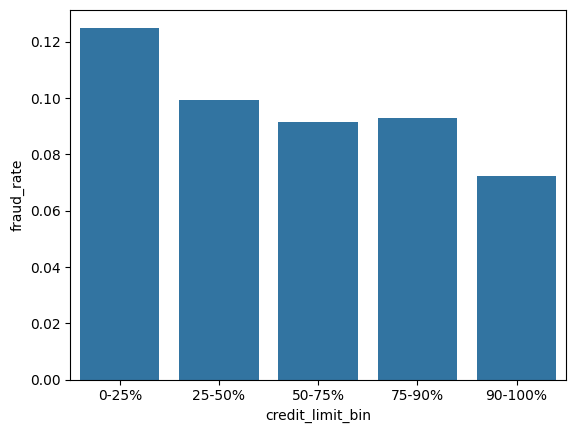

In [ ]:
sns.barplot(x=limit_fraud.index, y=limit_fraud['fraud_rate'])

### num_cards_issued vs target

,fraud_rate_pct
num_cards_issued,
1,0.150637
2,0.147877
3,0.189209


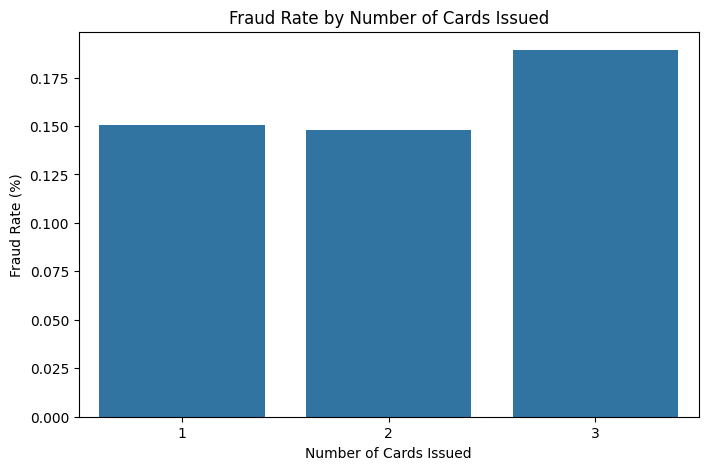

In [ ]:
cards_issued_fraud = master_df.groupby('num_cards_issued')['target_numeric'].mean() * 100

display(cards_issued_fraud.to_frame(name='fraud_rate_pct'))

plt.figure(figsize=(8, 5))
sns.barplot(x=cards_issued_fraud.index, y=cards_issued_fraud.values)
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Number of Cards Issued')
plt.title('Fraud Rate by Number of Cards Issued')
plt.show()

- Strong Card Features
  * card_type
  * credit_limit
  * num_cards_issued

- Moderate Features

  * card_brand

In [ ]:
master_df.to_parquet('master_df.parquet')

In [ ]:
master_df.isna().sum()

,0
date,0
time,0
card_id,0
amount,0
use_chip,0
merchant_id,0
merchant_city,0
merchant_state,1563700
zip,1652706
mcc,0
